# Examples of Superposition 2: Superposition in Space & Time

The original Theis solution assumes a pumping rate that starts at time 0 and continues forever. The Theis solution can be superposed *in time* to simulate the effect of variable pumping rates. Each time the pumping rate changes, a new Theis solution is superposed representing the change in flowrate.

We first demonstrate how the Theis solution can be shifted in time, and then demonstrate how to use this approach to superpose multiple solutions.

In [1]:
# GEOSCI-627 Class 15

#Import needed modules
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from scipy.integrate import quad

In [2]:
#Definitions of all solutions to be used, each presented in terms of head change
#relative to an initial value. In addition to outputting the head change, 
#each function outputs the depth-integrated discharge (-T*dh/dx, -T*dh/dy)

def WellFunc(u):
    Wu = sp.special.exp1(u)
    return Wu

def Theis_dh(Q, T, S, xw, yw, x, y, t):
    r = ((x-xw)**2 + (y-yw)**2)**(1/2)
    u = (S*r**2)/(4*T*t)
    Wu = WellFunc(u)
    #the np.where function is used to return a drawdown of 0 before t = 0
    dh = np.where(u > 0, -Q/(4*np.pi*T)*Wu, 0)
    qix = np.where(u > 0, -Q/(2*np.pi)*((x-xw)/(r**2))*np.exp(-u), 0)
    qiy = np.where(u > 0, -Q/(2*np.pi)*((y-yw)/(r**2))*np.exp(-u), 0)
    return dh, qix, qiy

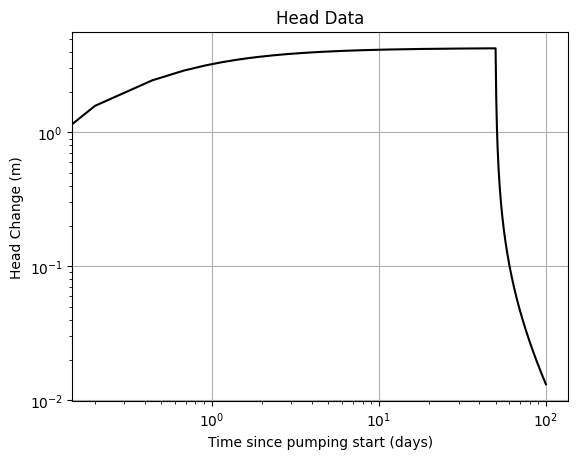

In [3]:
t = np.linspace(-20,100,500) #days
xw1, yw1 = 0, 0
xw2, yw2 = 300, 0
xo, yo = 50,0

#True parameter values
K = 0.15 # m/day
Ss = 1e-5 # 1/m
b = 10 #m
T = K*b
S = Ss*b

#Superposition in time for one well
Q1a = 25 # m^3/day
t_start1a = 0
dh1a, _, _ = Theis_dh(Q1a,T,S,xw1,yw1,xo,yo,(t-t_start1a))
Q1b = -25 #m^3/day
t_start1b = 50
dh1b, _, _ = Theis_dh(Q1b,T,S,xw1,yw1,xo,yo,(t-t_start1b))

#Superposition in time for a second well
Q2a = -25 # m^3/day
t_start2a = 0
dh2a, _, _ = Theis_dh(Q2a,T,S,xw2,yw2,xo,yo,(t-t_start2a))
Q2b = 25 #m^3/day
t_start2b = 50
dh2b, _, _ = Theis_dh(Q2b,T,S,xw2,yw2,xo,yo,(t-t_start2b))

dh_total = dh1a + dh2a + dh1b + dh2b
dd_total = -dh_total

fig, ax = plt.subplots()
#ax.plot(t,dh1,'-b')
#ax.plot(t,dh2,'-r')
ax.plot(t,dd_total, 'k')
ax.grid(visible='yes')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Time since pumping start (days)')
ax.set_ylabel('Head Change (m)')
ax.set_title('Head Data')
plt.show()



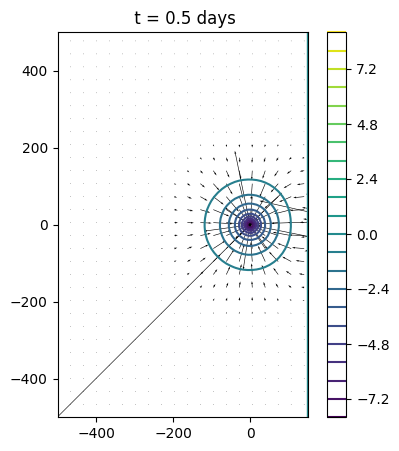

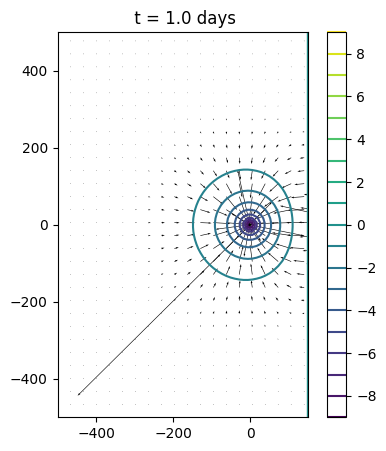

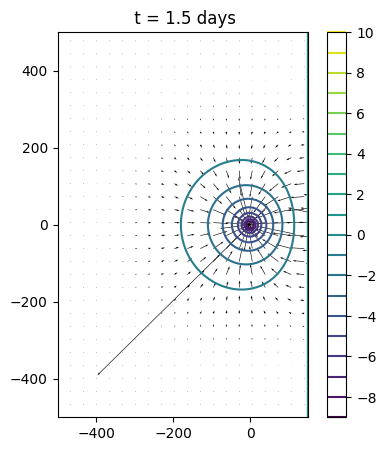

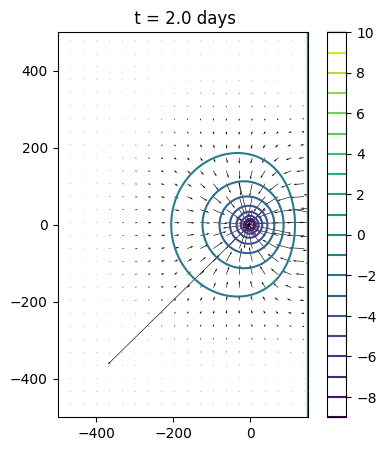

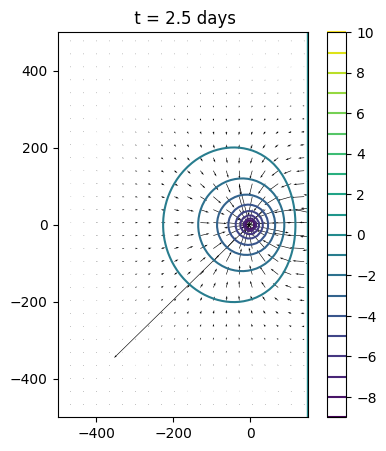

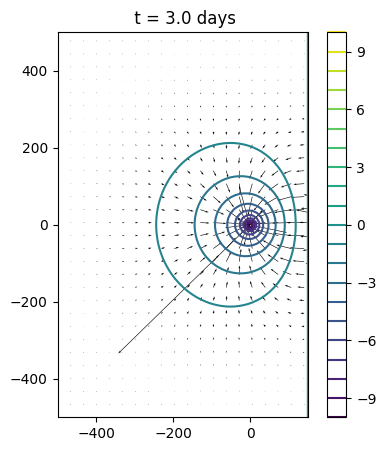

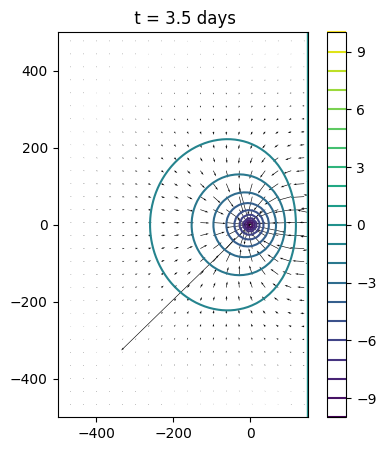

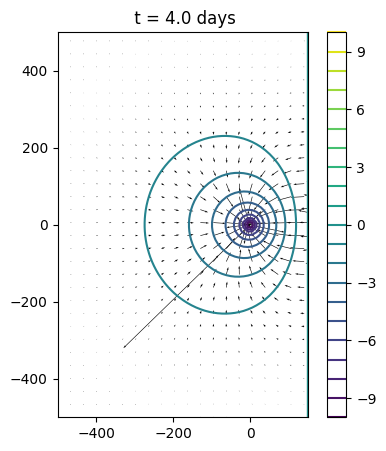

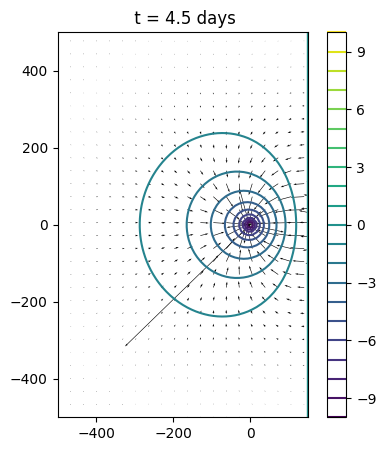

/var/folders/qk/f3wykhx514z39hxflxx5g66m0000gn/T/ipykernel_12921/635665602.py:11: RuntimeWarning: divide by zero encountered in divide
  u = (S*r**2)/(4*T*t)


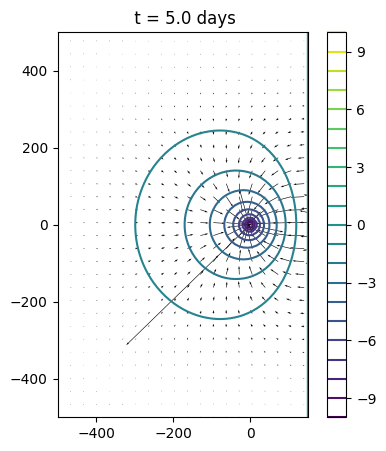

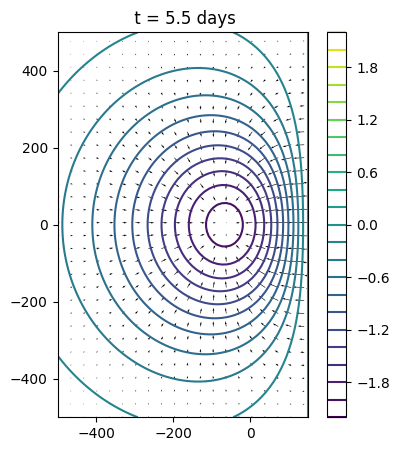

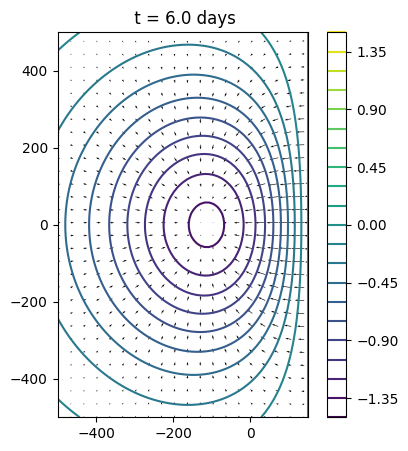

In [4]:
# 2-D Map of Drawdown over space for the case of pumping near a constant head boundary

x_coords = np.linspace(-500,500,90)
y_coords = np.linspace(-500,500,90)
xc,yc = np.meshgrid(x_coords,y_coords)
rc = (xc**2 + yc**2)**(1/2)

xw1, yw1 = 0, 0
xw2, yw2 = 300, 0
xo, yo = 50,0

#True parameter values
K = 0.15 # m/day
Ss = 1e-5 # 1/m
b = 10 #m
T = K*b
S = Ss*b

tlist = np.linspace(0.5,6,12)
for t in tlist:
    #Superposition in time for one well
    Q1a = 25 # m^3/day
    t_start1a = 0
    dh1a, qix1a, qiy1a = Theis_dh(Q1a,T,S,xw1,yw1,xc,yc,(t-t_start1a))
    Q1b = -25 #m^3/day
    t_start1b = 5
    dh1b, qix1b, qiy1b = Theis_dh(Q1b,T,S,xw1,yw1,xc,yc,(t-t_start1b))
    
    #Superposition in time for a second well
    Q2a = -25 # m^3/day
    t_start2a = 0
    dh2a, qix2a, qiy2a = Theis_dh(Q2a,T,S,xw2,yw2,xc,yc,(t-t_start2a))
    Q2b = 25 #m^3/day
    t_start2b = 5
    dh2b, qix2b, qiy2b = Theis_dh(Q2b,T,S,xw2,yw2,xc,yc,(t-t_start2b))
    
    dh_total = dh1a + dh1b + dh2a + dh2b
    qix_total = qix1a + qix1b + qix2a + qix2b
    qiy_total = qiy1a + qiy1b + qiy2a + qiy2b
    dd_total = -dh_total
        
    fig, ax = plt.subplots(figsize=(5, 5))
    #Add a contour plot to the axes
    contp = ax.contour(xc, yc, dh_total,levels=20)
    qfreq = 3
    quiv = ax.quiver(xc[::qfreq,::qfreq],
                     yc[::qfreq,::qfreq],
                     qix_total[::qfreq,::qfreq],
                     qiy_total[::qfreq,::qfreq],)
    
    ax.set_aspect('equal','box')
    ax.set_title(f" t = {t} days")
    ax.set_xlim(-500, 150)
    fig.colorbar(contp)
    plt.show()


